# Week 2 - Self-Attention from scratch (mRNA sequence)
Goal: understand and implement `Attention(Q, K, V) = softmax(Q·Kᵀ / √d_k) · V` with NumPy only, then apply it to an mRNA sequence.

- **Q (Query)**: what each position is looking for
- **K (Key)**: what each position offers to be matched against
- **V (Value)**: the content each position passes on once matched

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import attention as att

np.set_printoptions(precision=4, suppress=True)

## 1. A 3-token example you can do on paper
Take three tokens with 2-number embeddings, and use identity matrices as W_q, W_k, W_v so that Q = K = V = X (this keeps the arithmetic simple). Here d_k = 2, so √d_k = 1.4142.

x1 = [1, 0], x2 = [0, 1], x3 = [1, 1]

**Step 1 - scores Q·Kᵀ** (dot product of every pair): `[[1,0,1],[0,1,1],[1,1,2]]`

**Step 2 - divide by √2:** `[[0.7071, 0, 0.7071], [0, 0.7071, 0.7071], [0.7071, 0.7071, 1.4142]]`

**Step 3 - softmax each row.** Row 1: e^0.7071 = 2.028, e^0 = 1, e^0.7071 = 2.028, sum = 5.056, so weights = [0.401, 0.198, 0.401]. Row 3: 2.028, 2.028, 4.113, sum = 8.169, so weights = [0.248, 0.248, 0.503].

**Step 4 - multiply by V.** Output of token 1 = 0.401·[1,0] + 0.198·[0,1] + 0.401·[1,1] = [0.802, 0.599].

Now check the code against the hand calculation:

In [2]:
X_toy = np.array([[1., 0.], [0., 1.], [1., 1.]])
I = np.eye(2)
toy = att.attention_details(X_toy, d_k=2, W=(I, I, I))

print("scores / sqrt(d_k):\n", toy["scores"])
print("\nattention weights:\n", toy["weights"])
print("\nrow sums:", toy["weights"].sum(axis=1))
print("\noutput of token 1:", toy["output"][0], " (hand calculation: [0.802, 0.599])")

scores / sqrt(d_k):
 [[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]

attention weights:
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]

row sums: [1. 1. 1.]

output of token 1: [0.8022 0.5989]  (hand calculation: [0.802, 0.599])


## 2. Applying it to an mRNA sequence
Each base (A, C, G, U) gets a random 8-number embedding. The sequence becomes a (15 x 8) matrix, which is projected into Q, K and V.

In [3]:
sequence = 'ACGUACGUACGGCUA'
X = att.encode_sequence(sequence)
d = att.attention_details(X)

print("sequence length:", len(sequence))
print("X (embeddings):", X.shape)
for name in ["Q", "K", "V", "scores", "weights", "output"]:
    print(f"{name:8s}", d[name].shape)
print("\nevery row of the attention matrix sums to 1:", np.allclose(d["weights"].sum(axis=1), 1.0))

# input validation (FR-2.2): a wrong base must raise an error
try:
    att.encode_sequence('ACGX')
except ValueError as e:
    print("\nACGX ->", e)

sequence length: 15
X (embeddings): (15, 8)
Q        (15, 8)
K        (15, 8)
V        (15, 8)
scores   (15, 15)
weights  (15, 15)
output   (15, 8)

every row of the attention matrix sums to 1: True

ACGX -> Invalid character(s) in mRNA sequence: 'X' at position 4. Only ['A', 'C', 'G', 'U'] (uppercase) are allowed.


## 3. The attention heatmap
Rows = the position that is attending (FROM), columns = the position being attended to (TO). The final heatmap file `outputs/figures/attention_heatmap.png` is made by `python src/attention.py`.

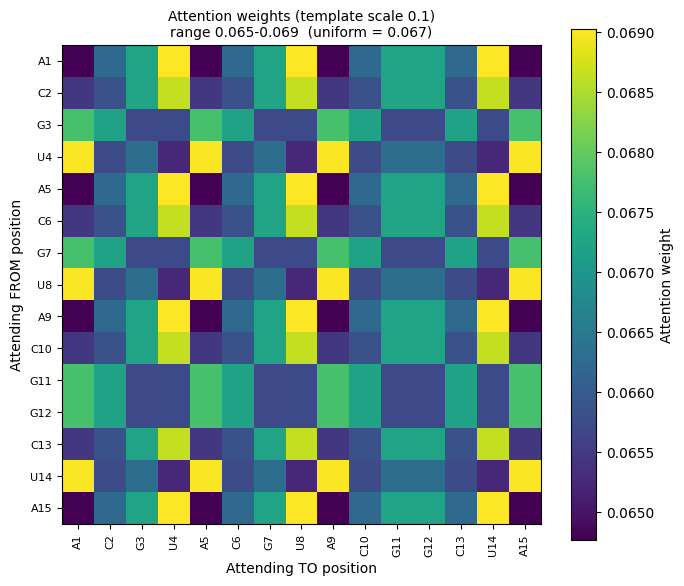

In [4]:
def show(ax, w, seq, title):
    n = len(seq)
    labels = att.position_labels(seq)
    im = ax.imshow(w, cmap='viridis')
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=90, fontsize=8); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Attending TO position'); ax.set_ylabel('Attending FROM position')
    ax.set_title(f"{title}\nrange {w.min():.3f}-{w.max():.3f}  (uniform = {1/n:.3f})", fontsize=10)
    return im

fig, ax = plt.subplots(figsize=(7, 6))
im = show(ax, d["weights"], sequence, "Attention weights (template scale 0.1)")
fig.colorbar(im, ax=ax, label='Attention weight')
fig.tight_layout()
plt.show()

**Reading the heatmap above:** every cell is between 0.065 and 0.069, almost exactly the uniform value 1/15 = 0.067. The colours only look dramatic because the colour bar is stretched over this tiny range. The reason: the weight matrices are multiplied by 0.1, so the scores Q·Kᵀ are tiny and softmax of tiny numbers is nearly uniform.

average attention weight, scale 1.0   (columns: A, C, G, U)
A [0.001 0.005 0.022 0.297]
C [0.002 0.004 0.036 0.276]
G [0.165 0.072 0.007 0.008]
U [0.243 0.002 0.005 0.001]

rows of A1 and A5 identical: True


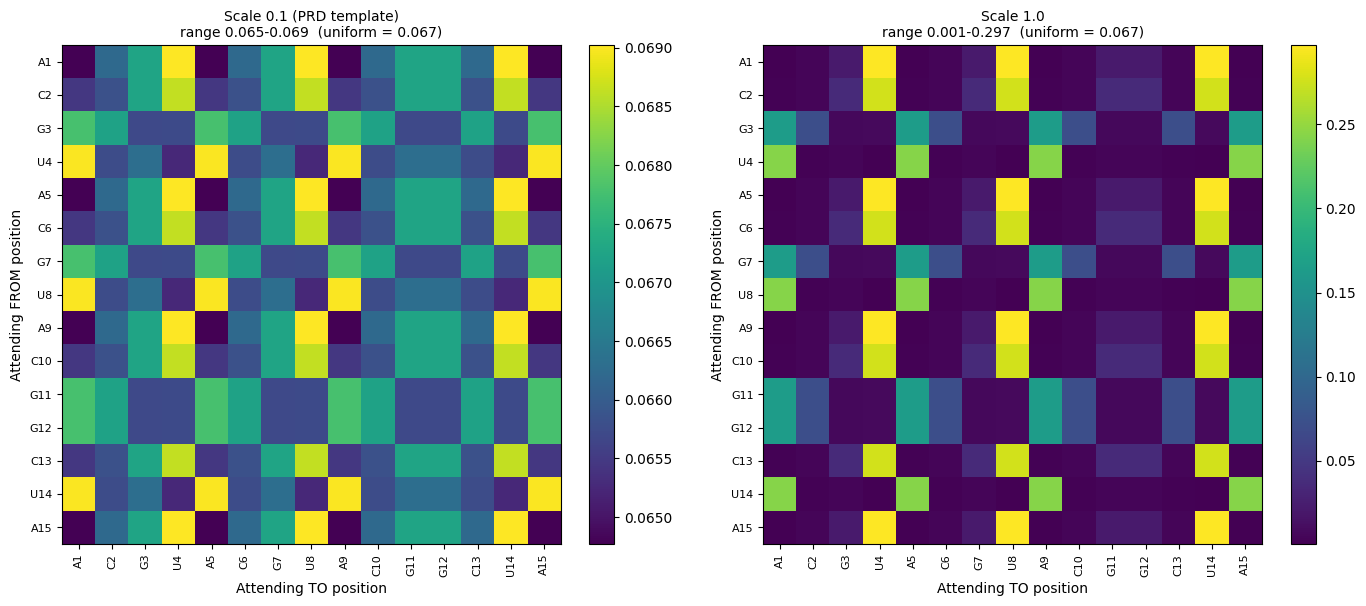

In [5]:
# Same sequence, same seed, but projection weights 10x larger
big = att.attention_details(X, weight_scale=1.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = show(axes[0], d["weights"], sequence, "Scale 0.1 (PRD template)")
im1 = show(axes[1], big["weights"], sequence, "Scale 1.0")
fig.colorbar(im0, ax=axes[0], fraction=0.046); fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()
plt.show()

# average attention that a base (row) pays to each base (column)
print("average attention weight, scale 1.0   (columns: A, C, G, U)")
for f in 'ACGU':
    row = [np.mean([big["weights"][i, j] for i in range(15) for j in range(15)
                    if sequence[i] == f and sequence[j] == t]) for t in 'ACGU']
    print(f, np.round(row, 3))
print("\nrows of A1 and A5 identical:", np.allclose(big["weights"][0], big["weights"][4]))

## 4. Bonus - multi-head attention
Run the mechanism 3 times with independent random Q/K/V weights and concatenate the outputs. Each head can attend to different things.

per-head weight matrices: [(15, 15), (15, 15), (15, 15)]
concatenated output: (15, 24) = (15, 3 heads x 8)


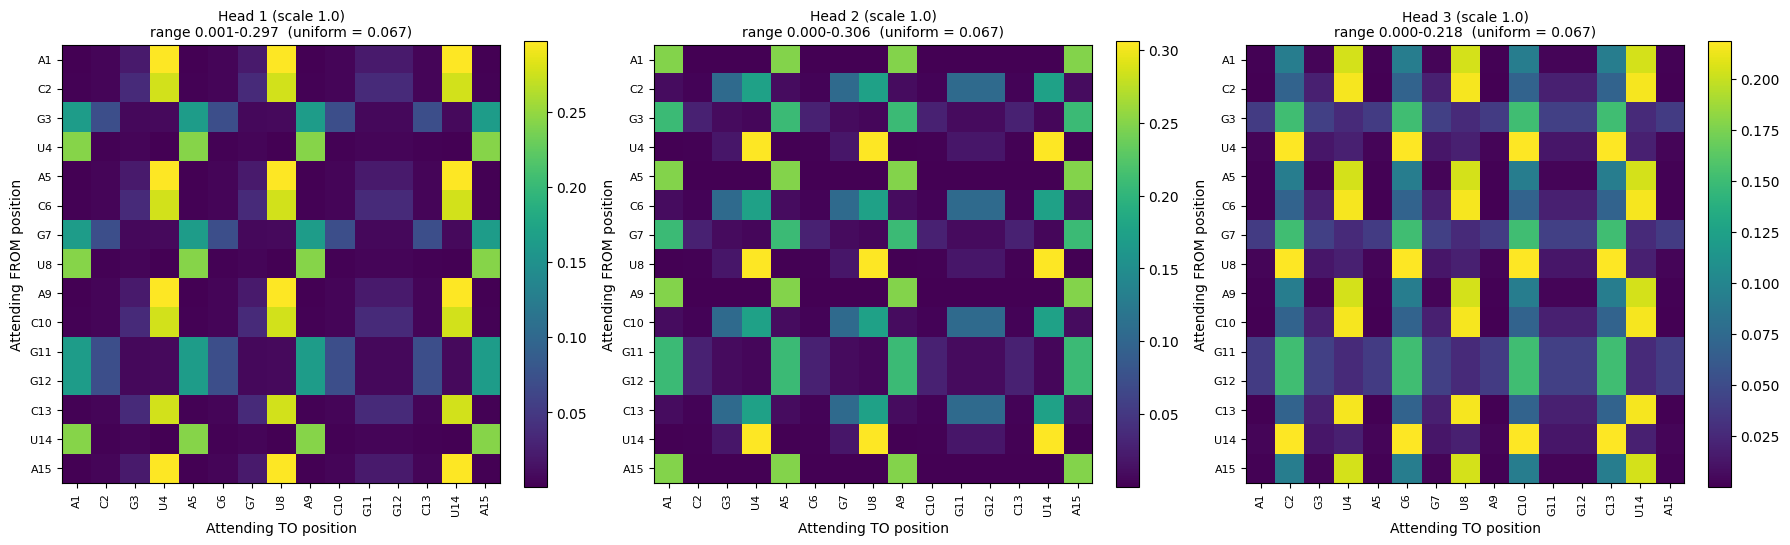

In [6]:
heads_w, heads_out = att.multi_head_attention(X, num_heads=3, weight_scale=1.0)
print("per-head weight matrices:", [h.shape for h in heads_w])
print("concatenated output:", heads_out.shape, "= (15, 3 heads x 8)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for k, (ax, w) in enumerate(zip(axes, heads_w)):
    im = show(ax, w, sequence, f"Head {k + 1} (scale 1.0)")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

## 5. Interpretation
- With the template's small weights, attention is almost uniform (0.065-0.069). Small preferences exist: A and C rows lean slightly towards U, G and U rows towards A, and each base attends least to itself.
- With 10x larger weights the same preferences become strong: A and C attend mostly to U (about 0.3), U attends to A (about 0.24), and G attends to A (about 0.16).
- Identical bases have identical rows (A1 = A5 = A9, ...), because there is no positional encoding, so attention depends only on which base it is.
- These preferences come only from random initialisation. They are not biological knowledge; a trained model would learn them from data. The full written explanation is in `outputs/reports/week2_attention_explanation.md`.